# MobileNetV3-Large — DeepWeeds original-paper split protocol

**Workflow:** setup → download original images.zip → download original labels from github → tune learning rate on the original five **training/validation** pairs → select learning rate → evaluate five selected fold-specific models on their corresponding **test** subsets → per-class / session / time error analysis.


**Safe defaults:** All training and test inference toggles start as `False`. For new runtimes, switch them back on if necessary.

## 1. Colab setup and image extraction

In [1]:
from pathlib import Path
import sys, subprocess, shutil, random, copy, gc, zipfile
import numpy as np
import pandas as pd
import torch
from google.colab import drive

# Define path variables
drive.mount('/content/drive')
PROJECT = Path('/content/CS3244-DeepWeeds')
DRIVE = Path('/content/drive/MyDrive/CS3244-DeepWeeds')
PAPER = DRIVE / 'paper_splits'                 # Separate from grouped experiments
CHECKPOINTS = PAPER / 'checkpoints'
OUT = PAPER / 'error_analysis'
LABELS = PROJECT / 'data' / 'original_paper_labels'
if not (PROJECT / 'src/data_pipeline.py').is_file():
    if PROJECT.exists():
        raise RuntimeError(f'Project folder exists but src/data_pipeline.py is missing: {PROJECT}')
    subprocess.run(['git', 'clone', 'https://github.com/Teamoreteateo/CS3244-DeepWeeds.git', str(PROJECT)], check=True)
for p in [PAPER, CHECKPOINTS, OUT, LABELS]:
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT / 'src'))
from data import IMG_DIR
from data_pipeline import DeepWeedsDataset, make_transforms
from metrics import SPECIES

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else DEVICE)
print('Paper results folder:', PAPER)

Mounted at /content/drive
Device: NVIDIA A100-SXM4-40GB
Paper results folder: /content/drive/MyDrive/CS3244-DeepWeeds/paper_splits


In [2]:
# Skip extraction when all 17,509 images are already present.
images = list(IMG_DIR.glob('*.jpg')) if IMG_DIR.exists() else []
if len(images) != 17509:
    zip_candidates = [DRIVE/'images.zip', PROJECT/'data/images.zip', PROJECT/'images.zip']
    archive = next((p for p in zip_candidates if p.is_file() and zipfile.is_zipfile(p)), None)
    if archive is None:
        raise FileNotFoundError('Place a valid 17,509-image images.zip in Drive/CS3244-DeepWeeds or PROJECT/data/')
    IMG_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        jpgs = [p for p in z.namelist() if p.lower().endswith('.jpg')]
        if len(jpgs) != 17509 or any('/' in p.strip('/') for p in jpgs):
            raise ValueError('Expected 17,509 JPGs at the archive root; inspect the ZIP layout.')
        z.extractall(IMG_DIR)
assert len(list(IMG_DIR.glob('*.jpg'))) == 17509
print('Image count: 17,509')

Image count: 17,509


## 2. Obtain the original published splits and check for exact overlap

These label lists come directly from the [original DeepWeeds repository](https://github.com/AlexOlsen/DeepWeeds/tree/master/labels). The study deliberately follows those original subsets, **without** enforcing session disjointness. We still check that filenames do not overlap inside each fold.

In [3]:
from urllib.request import urlretrieve
BASE_URL = 'https://raw.githubusercontent.com/AlexOlsen/DeepWeeds/master/labels'

for fold in range(5):
    for partition in ('train', 'val', 'test'):
        name = f'{partition}_subset{fold}.csv'
        destination = LABELS / name
        if not destination.exists():
            urlretrieve(f'{BASE_URL}/{name}', destination)

splits = {}
for fold in range(5):
    splits[fold] = {}
    for partition in ('train', 'val', 'test'):
        frame = pd.read_csv(LABELS / f'{partition}_subset{fold}.csv')
        assert {'Filename','Label'}.issubset(frame.columns)
        frame = frame[['Filename','Label']].copy()
        frame['Label'] = frame['Label'].astype(int)
        assert frame['Filename'].is_unique
        assert frame['Label'].between(0,8).all()
        # DeepWeeds names: YYYYMMDD-HHMMSS-instrument.jpg.
        # Session here is defined by date + instrument, for descriptive analysis only.
        match = frame['Filename'].str.extract(r'^(\d{8})-(\d{6})-(\d+)\.jpg$')
        assert match.notna().all().all(), 'Unexpected original filename format'
        frame['date'] = match[0]
        frame['hour'] = match[1].str[:2].astype(int)
        frame['instrument'] = match[2]
        frame['session'] = match[0] + '-' + match[2]
        frame['Species'] = frame['Label'].map(dict(enumerate(SPECIES)))
        frame['fold'] = fold
        splits[fold][partition] = frame

for fold, parts in splits.items():
    a,b,c = (parts[p] for p in ('train','val','test'))
    fn = [set(v['Filename']) for v in (a,b,c)]
    assert not (fn[0] & fn[1] or fn[0] & fn[2] or fn[1] & fn[2]), f'Filename leakage in fold {fold}'
    print(f'Fold {fold}: train={len(a)}, val={len(b)}, test={len(c)}; '
          f'train–val shared sessions={len(set(a.session)&set(b.session))}; '
          f'train–test shared sessions={len(set(a.session)&set(c.session))}')

# Five test lists should cover the 17,509 dataset images once in total.
all_tests = pd.concat([splits[i]['test'] for i in range(5)], ignore_index=True)
assert len(all_tests) == 17509 and all_tests['Filename'].is_unique,     'Unexpected repeated/omitted test filename across original folds'
print('Verified: every image appears in exactly one original test subset.')

Fold 0: train=10501, val=3501, test=3507; train–val shared sessions=99; train–test shared sessions=100
Fold 1: train=10504, val=3502, test=3503; train–val shared sessions=99; train–test shared sessions=100
Fold 2: train=10506, val=3502, test=3501; train–val shared sessions=100; train–test shared sessions=98
Fold 3: train=10506, val=3503, test=3500; train–val shared sessions=100; train–test shared sessions=100
Fold 4: train=10508, val=3503, test=3498; train–val shared sessions=99; train–test shared sessions=97
Verified: every image appears in exactly one original test subset.


## 3. Five-fold learning-rate comparison — original validation subsets

Each (LR, fold) experiment starts with ImageNet-pretrained MobileNetV3-Large, trains on **`train_subset{fold}.csv` only**, and selects its best epoch using **`val_subset{fold}.csv`**. The five test subsets are not used for tuning. Training parameters match your previous experiment: 20 epochs, batch size 16, AdamW, weight decay `1e-4`, cross-entropy, training augmentation.

**Old LR results (0.8398/0.8273/0.8304) belong to grouped CV; they must not be reported as results for this new split.**

In [10]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

LEARNING_RATES = [0.00005, 0.0001, 0.0002]
EPOCHS = 20
BATCH_SIZE = 16
NUM_WORKERS = 4
RUN_CV = True      # Set True to train missing paper-split models (15 runs total)

def lr_tag(lr):
    return f'{lr:.5f}'.rstrip('0').rstrip('.')

def ckpt_path(lr, fold):
    return CHECKPOINTS / f'mobilenetv3_paper_lr{lr_tag(lr)}_fold{fold}.pt'

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def loader_for(frame, augment, batch_size=BATCH_SIZE, shuffle=False):
    ds = DeepWeedsDataset(frame, IMG_DIR, make_transforms(augment), SPECIES)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS)

def new_model(pretrained):
    weights = MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
    model = mobilenet_v3_large(weights=weights)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, 9)
    return model.to(DEVICE)

@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    rows = []
    for images, labels, names in loader:
        probabilities = model(images.to(DEVICE)).softmax(dim=1)
        confidence, predicted = probabilities.max(dim=1)
        rows.extend({'Filename':name, 'true_label':int(actual),
                     'predicted_label':int(pred), 'confidence':float(conf)}
                    for name, actual, pred, conf in zip(
                        names, labels.tolist(), predicted.cpu().tolist(), confidence.cpu().tolist()))
    return pd.DataFrame(rows)

def score(preds):
    y, p = preds['true_label'].to_numpy(), preds['predicted_label'].to_numpy()
    weeds = y != 8
    return dict(macro_f1=float(f1_score(y,p,labels=range(9),average='macro',zero_division=0)),
                accuracy=float(accuracy_score(y,p)),
                weighted_f1=float(f1_score(y,p,labels=range(9),average='weighted',zero_division=0)),
                weed_to_negative_rate=float((p[weeds]==8).mean()) if weeds.any() else float('nan'))

def train_one(lr, fold):
    set_seed(42)
    train_loader = loader_for(splits[fold]['train'], augment=True, shuffle=True)
    val_loader = loader_for(splits[fold]['val'], augment=False)
    model = new_model(pretrained=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    best_f1 = -1.0
    best_state, best_metrics, best_epoch = None, None, None
    for epoch in range(1, EPOCHS+1):
        model.train()
        total_loss = 0.0
        for images, labels, _ in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(images), labels)
            loss.backward(); opt.step()
            total_loss += loss.item() * len(labels)
        metrics = score(predict_loader(model, val_loader))
        print(f'LR={lr}, fold={fold}, epoch={epoch}/{EPOCHS}: '
              f'loss={total_loss/len(train_loader.dataset):.4f}, '
              f'val macro-F1={metrics["macro_f1"]:.4f}', flush=True)
        if metrics['macro_f1'] > best_f1:
            best_f1 = metrics['macro_f1']; best_metrics = metrics; best_epoch = epoch
            best_state = {key: value.detach().cpu().clone() for key,value in model.state_dict().items()}
    checkpoint = {'state_dict':best_state, 'fold':fold, 'learning_rate':lr,
                  'best_epoch':best_epoch, 'validation_metrics':best_metrics,
                  'split_protocol':'DeepWeeds original train/val/test subset CSVs'}
    torch.save(checkpoint, ckpt_path(lr,fold))
    del model, opt, best_state
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return best_metrics

if RUN_CV:
    for lr in LEARNING_RATES:
        for fold in range(5):
            if ckpt_path(lr,fold).exists():
                print('Skipping saved paper model:', ckpt_path(lr,fold).name)
            else:
                train_one(lr,fold)
else:
    print('Paper-split CV training disabled; set RUN_CV=True when ready.')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 79.5MB/s]


LR=5e-05, fold=0, epoch=1/20: loss=0.9617, val macro-F1=0.8103
LR=5e-05, fold=0, epoch=2/20: loss=0.4726, val macro-F1=0.8700
LR=5e-05, fold=0, epoch=3/20: loss=0.3635, val macro-F1=0.8873
LR=5e-05, fold=0, epoch=4/20: loss=0.2944, val macro-F1=0.9116
LR=5e-05, fold=0, epoch=5/20: loss=0.2560, val macro-F1=0.9276
LR=5e-05, fold=0, epoch=6/20: loss=0.2304, val macro-F1=0.9210
LR=5e-05, fold=0, epoch=7/20: loss=0.2082, val macro-F1=0.9387
LR=5e-05, fold=0, epoch=8/20: loss=0.1876, val macro-F1=0.9353
LR=5e-05, fold=0, epoch=9/20: loss=0.1650, val macro-F1=0.9438
LR=5e-05, fold=0, epoch=10/20: loss=0.1581, val macro-F1=0.9450
LR=5e-05, fold=0, epoch=11/20: loss=0.1411, val macro-F1=0.9424
LR=5e-05, fold=0, epoch=12/20: loss=0.1273, val macro-F1=0.9441
LR=5e-05, fold=0, epoch=13/20: loss=0.1191, val macro-F1=0.9494
LR=5e-05, fold=0, epoch=14/20: loss=0.1058, val macro-F1=0.9465
LR=5e-05, fold=0, epoch=15/20: loss=0.1060, val macro-F1=0.9426
LR=5e-05, fold=0, epoch=16/20: loss=0.0974, val m

### Validation results and learning-rate selection

Choose the learning rate by **mean validation macro-F1 across five complete original-paper folds**. Do not mix in the older grouped-CV checkpoints.

In [11]:
records = []
for lr in LEARNING_RATES:
    for fold in range(5):
        path = ckpt_path(lr,fold)
        if path.is_file():
            checkpoint = torch.load(path,map_location='cpu',weights_only=False)  # Your own checkpoints only
            m = checkpoint['validation_metrics']
            records.append({'learning_rate':lr, 'fold':fold,
                            'best_epoch':checkpoint.get('best_epoch',np.nan),
                            **{k:float(v) for k,v in m.items()}})
        else:
            print(f'Missing paper split checkpoint: LR={lr}, fold={fold}')

if not records:
    print('No paper-split models found. Enable RUN_CV above and run that training cell first.')
    BEST_LR = None
else:
    cv_results = pd.DataFrame(records)
    cv_summary = cv_results.groupby('learning_rate').agg(
        folds=('fold','nunique'),mean_macro_f1=('macro_f1','mean'),
        std_macro_f1=('macro_f1','std'),mean_accuracy=('accuracy','mean'),
        mean_weighted_f1=('weighted_f1','mean'),
        mean_weed_to_negative=('weed_to_negative_rate','mean')
    ).sort_values('mean_macro_f1',ascending=False) # Select LR that has the highest mean macro F1 score
    print(cv_summary.round(4).to_string())
    complete = cv_summary.loc[cv_summary.folds==5]
    BEST_LR = float(complete.index[0]) if len(complete) else None
    print('Selected LR from complete paper folds:', BEST_LR)
    cv_results.to_csv(OUT/'paper_cv_fold_metrics.csv',index=False)
    cv_summary.to_csv(OUT/'paper_cv_summary.csv')

               folds  mean_macro_f1  std_macro_f1  mean_accuracy  mean_weighted_f1  mean_weed_to_negative
learning_rate                                                                                            
0.00010            5         0.9534        0.0038         0.9630            0.9629                 0.0334
0.00005            5         0.9523        0.0034         0.9629            0.9629                 0.0258
0.00020            5         0.9479        0.0044         0.9599            0.9600                 0.0272
Selected LR from complete paper folds: 0.0001


## 4. Evaluate the selected fold models on the five original test subsets

**Different from the earlier grouped workflow:** no additional single 13,274-image final model. Instead, use the validation-selected checkpoint **from each fold**, predict on `test_subset{fold}.csv` only, and aggregate test predictions across the five disjoint test subsets. This matches the five-fold train/validation/test evaluation design; you can also report mean and standard deviation of the five test-fold scores.

Do not use test performance to choose a learning rate or retrain. These results are **not directly comparable** to the earlier 4,235-image grouped test evaluation.

In [13]:
RUN_TEST_INFERENCE = True  # Turn on only after BEST_LR is selected
PREDICTIONS = OUT / 'mobilenetv3_paper_test_predictions.csv'

if RUN_TEST_INFERENCE:
    if BEST_LR is None:
        raise RuntimeError('Complete all 5 original validation folds for at least one LR first.')
    all_predictions = []
    for fold in range(5):
        path = ckpt_path(BEST_LR,fold)
        if not path.is_file(): raise FileNotFoundError(path)
        checkpoint = torch.load(path,map_location='cpu',weights_only=False)
        model = new_model(pretrained=False)
        model.load_state_dict(checkpoint['state_dict'])
        test_loader = loader_for(splits[fold]['test'],augment=False,batch_size=32)
        preds = predict_loader(model,test_loader)
        preds = preds.merge(splits[fold]['test'][['Filename','Species','date','hour','instrument','session','fold']],
                            on='Filename',validate='one_to_one')
        all_predictions.append(preds)
        print(f'Test fold {fold}:',score(preds))
        del model
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    combined = pd.concat(all_predictions,ignore_index=True)
    assert len(combined)==17509 and combined.Filename.is_unique
    combined.to_csv(PREDICTIONS,index=False)
    print('Saved all paper test-fold predictions:',PREDICTIONS)
else:
    print('Test inference skipped; existing paper prediction file:',PREDICTIONS.is_file())

Test fold 0: {'macro_f1': 0.950771522656949, 'accuracy': 0.9597946963216424, 'weighted_f1': 0.9597646706635664, 'weed_to_negative_rate': 0.03382789317507418}
Test fold 1: {'macro_f1': 0.9505573145063025, 'accuracy': 0.9628889523265772, 'weighted_f1': 0.9623977692128726, 'weed_to_negative_rate': 0.03804994054696789}
Test fold 2: {'macro_f1': 0.9467587833572915, 'accuracy': 0.9568694658668951, 'weighted_f1': 0.9570812182001824, 'weed_to_negative_rate': 0.027976190476190477}
Test fold 3: {'macro_f1': 0.9418135305842027, 'accuracy': 0.9537142857142857, 'weighted_f1': 0.9535316692927396, 'weed_to_negative_rate': 0.04645622394282311}
Test fold 4: {'macro_f1': 0.9517057172833786, 'accuracy': 0.9614065180102916, 'weighted_f1': 0.9612212394859949, 'weed_to_negative_rate': 0.03995229576624926}
Saved all paper test-fold predictions: /content/drive/MyDrive/CS3244-DeepWeeds/paper_splits/error_analysis/mobilenetv3_paper_test_predictions.csv


## 5. Aggregate performance, per-class results, and confusion matrix

=== Pooled five-test-fold metrics ===
{'macro_f1': 0.9482968829487431, 'accuracy': 0.9589354046490376, 'weighted_f1': 0.9587881463962401, 'weed_to_negative_rate': 0.037248601689872665}
=== Test fold scores ===
 fold  macro_f1  accuracy  weighted_f1  weed_to_negative_rate
    0    0.9508    0.9598       0.9598                 0.0338
    1    0.9506    0.9629       0.9624                 0.0380
    2    0.9468    0.9569       0.9571                 0.0280
    3    0.9418    0.9537       0.9535                 0.0465
    4    0.9517    0.9614       0.9612                 0.0400
Mean test-fold macro-F1: 0.9483213736776248
Std test-fold macro-F1: 0.004100309539834745
                precision  recall  f1-score  support
Chinee apple       0.9191  0.8881    0.9033   1126.0
Lantana            0.9716  0.9332    0.9520   1063.0
Parkinsonia        0.9638  0.9806    0.9721   1031.0
Parthenium         0.9555  0.9658    0.9606   1022.0
Prickly acacia     0.9502  0.9350    0.9426   1062.0
Rubber vine

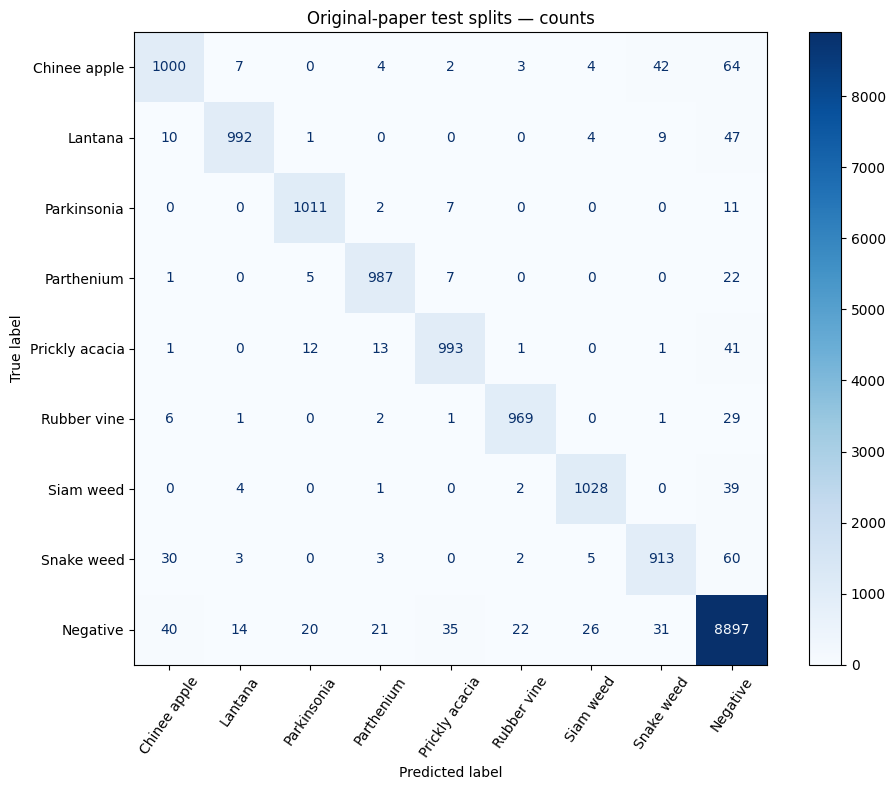

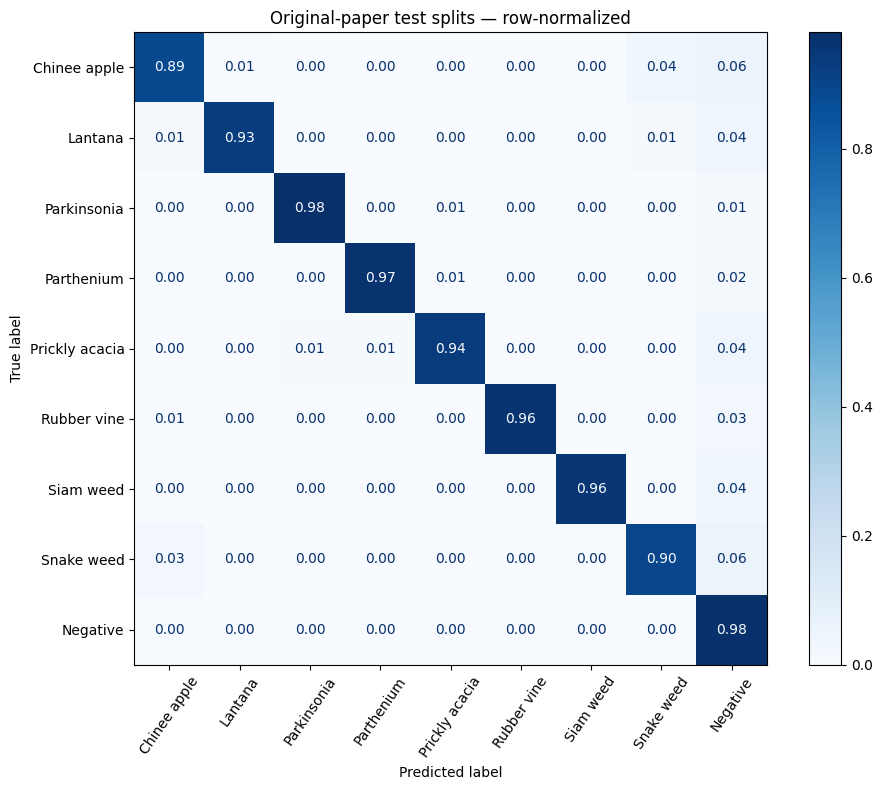

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

if not PREDICTIONS.exists():
    print('Paper-split test predictions are not available. Enable RUN_TEST_INFERENCE above after CV.')
else:
    df = pd.read_csv(PREDICTIONS)
    assert len(df)==17509 and df.Filename.is_unique
    classes = list(SPECIES)
    print('=== Pooled five-test-fold metrics ===')
    print(score(df))
    fold_test_metrics = pd.DataFrame([{'fold':fold,**score(group)} for fold,group in df.groupby('fold')])
    print('=== Test fold scores ===')
    print(fold_test_metrics.round(4).to_string(index=False))
    print('Mean test-fold macro-F1:',fold_test_metrics.macro_f1.mean())
    print('Std test-fold macro-F1:',fold_test_metrics.macro_f1.std())
    fold_test_metrics.to_csv(OUT/'paper_test_fold_metrics.csv',index=False)

    y_true,y_pred = df.true_label.to_numpy(),df.predicted_label.to_numpy()
    classification = pd.DataFrame(classification_report(
        y_true,y_pred,labels=list(range(9)),target_names=classes,
        zero_division=0,output_dict=True)).T
    print(classification.loc[classes].round(4).to_string())
    classification.to_csv(OUT/'paper_per_class_metrics.csv')
    errors = df[df.true_label != df.predicted_label]
    print('Most common errors:')
    for (a,b),count in errors.groupby(['true_label','predicted_label']).size().nlargest(10).items():
        print(f'{classes[int(a)]} -> {classes[int(b)]}: {count}')

    cm=confusion_matrix(y_true,y_pred,labels=range(9))
    for normalized in (False,True):
        values=cm/np.maximum(cm.sum(axis=1,keepdims=True),1) if normalized else cm
        fig,ax=plt.subplots(figsize=(10,8))
        ConfusionMatrixDisplay(values,display_labels=classes).plot(
            ax=ax,cmap='Blues',values_format='.2f' if normalized else 'd',xticks_rotation=55)
        ax.set_title('Original-paper test splits — '+('row-normalized' if normalized else 'counts'))
        fig.tight_layout()
        fig.savefig(OUT/f'paper_confusion_{"normalized" if normalized else "counts"}.png',dpi=180)
        plt.show()

## 6. Error analysis: recording group and time of day

**Caution:** The original split shares date–instrument groups between training, validation and test. Session/time trends here are **descriptive**, not evidence of generalization to unseen sessions. Time-of-day and species distributions may be confounded.

In [15]:
if not PREDICTIONS.exists():
    print('Run original-paper test inference before error analysis.')
else:
    df = pd.read_csv(PREDICTIONS)
    df['correct'] = df.true_label.eq(df.predicted_label)
    df['species'] = df.true_label.map(dict(enumerate(SPECIES)))
    if 'hour' not in df.columns:
        df['hour'] = df.Filename.str.extract(r'^\d{8}-(\d{2})\d{4}-\d+\.jpg$')[0].astype(int)
    session_rows=[]
    for session,group in df.groupby('session'):
        y,p=group.true_label.to_numpy(),group.predicted_label.to_numpy()
        weeds=y!=8
        counts=group.true_label.value_counts()
        session_rows.append({'session':session,'images':len(group),'accuracy':(y==p).mean(),
                             'dominant_class':SPECIES[int(counts.idxmax())],
                             'dominant_share':counts.max()/len(group),
                             'weed_to_negative_rate':(p[weeds]==8).mean() if weeds.any() else np.nan})
    session_results=pd.DataFrame(session_rows).sort_values('accuracy')
    session_results.to_csv(OUT/'paper_session_analysis.csv',index=False)
    print('Sessions with lowest accuracy:')
    print(session_results.head(15).round(4).to_string(index=False))

    df['time_period']=pd.cut(df.hour,bins=[0,9,12,15,24],right=False,
        labels=['Early morning (<09:00)','Morning (09:00–11:59)',
                'Midday (12:00–14:59)','Late afternoon (15:00+)'])
    time_results=df.groupby('time_period',observed=True).agg(
        images=('correct','size'),accuracy=('correct','mean'),
        sessions=('session','nunique')).reset_index()
    print('Time-of-day accuracy:')
    print(time_results.round(4).to_string(index=False))
    time_results.to_csv(OUT/'paper_time_analysis.csv',index=False)
    species_time=df.groupby(['species','time_period'],observed=True).agg(
        images=('correct','size'),accuracy=('correct','mean')).reset_index()
    species_time.to_csv(OUT/'paper_species_time_analysis.csv',index=False)

Sessions with lowest accuracy:
   session  images  accuracy dominant_class  dominant_share  weed_to_negative_rate
20170803-1      11    0.3636   Chinee apple          0.9091                 0.1818
20170521-0       7    0.4286        Lantana          1.0000                 0.0000
20170804-1      10    0.6000        Lantana          0.5000                 0.3000
20170704-0      69    0.6377     Snake weed          0.6232                 0.2000
20170706-0      58    0.6379     Snake weed          0.9138                 0.2500
20170721-1       3    0.6667   Chinee apple          0.6667                 0.0000
20170711-0      48    0.7708   Chinee apple          0.6875                 0.1915
20170610-0      75    0.7867        Lantana          1.0000                 0.1733
20170707-0      48    0.8125   Chinee apple          0.6042                 0.1087
20161207-0      64    0.8281   Chinee apple          0.7344                 0.1333
20170405-0      48    0.8333   Chinee apple          0.9

## 7. Inspect high-confidence errors (optional)

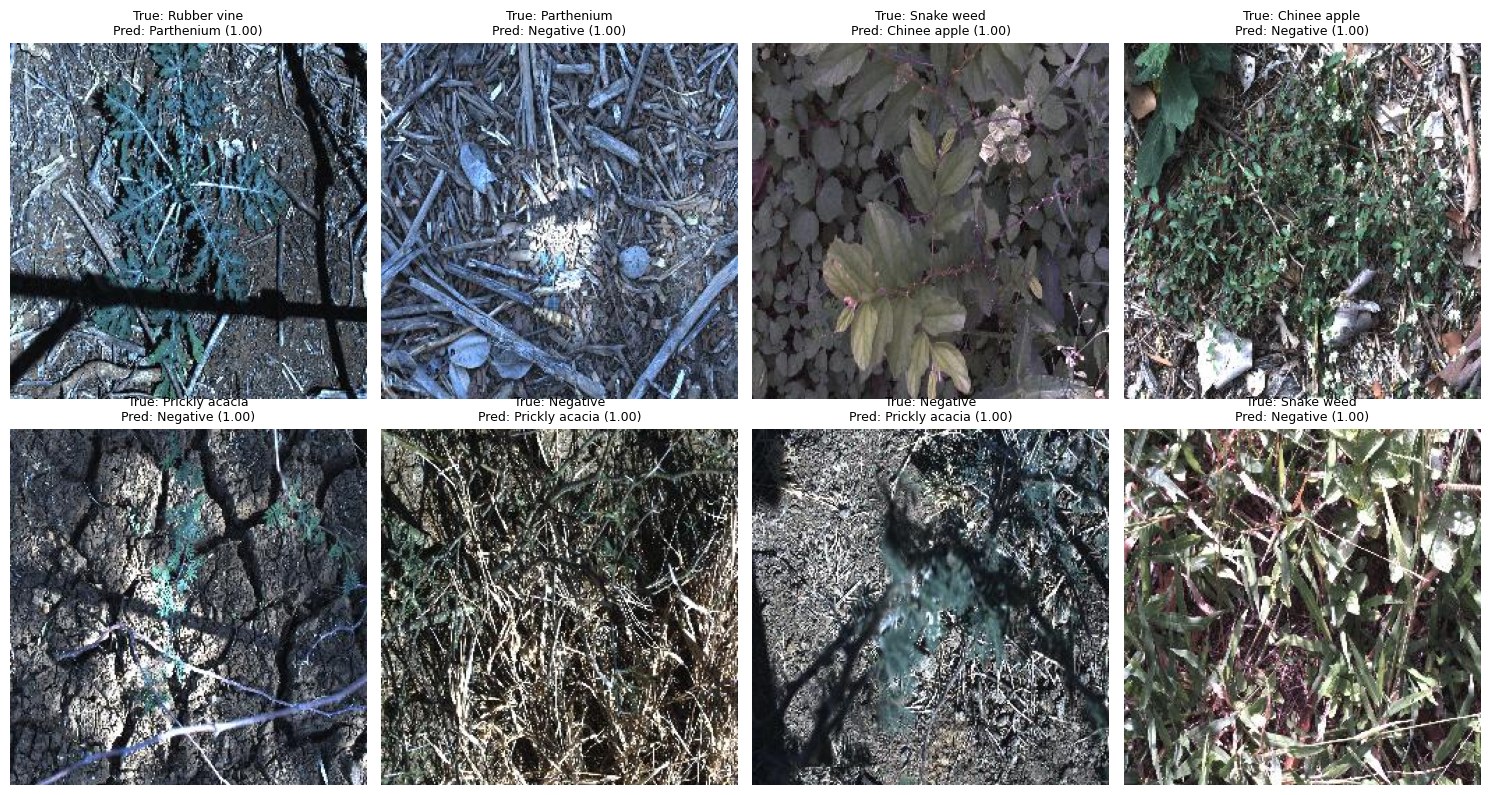

In [16]:
if not PREDICTIONS.exists():
    print('Run paper-split test inference first.')
else:
    from PIL import Image
    df=pd.read_csv(PREDICTIONS)
    mistakes=df[df.true_label != df.predicted_label].sort_values('confidence',ascending=False).head(8)
    fig,axes=plt.subplots(2,4,figsize=(15,8))
    for ax in axes.ravel(): ax.axis('off')
    for ax,(_,row) in zip(axes.ravel(),mistakes.iterrows()):
        with Image.open(IMG_DIR/row.Filename) as im: ax.imshow(im.convert('RGB'))
        ax.set_title(f'True: {SPECIES[int(row.true_label)]}\nPred: {SPECIES[int(row.predicted_label)]} ({row.confidence:.2f})',fontsize=9)
    fig.tight_layout()
    fig.savefig(OUT/'paper_high_confidence_errors.png',dpi=180)
    plt.show()

## Report notes / methodological caution

- **Original-paper protocol:** Use `train_subset{k}.csv`, `val_subset{k}.csv`, `test_subset{k}.csv` for each fold `k`; five test subsets are distinct, covering all 17,509 images. Select LR using validation only, then report five test-fold scores or aggregate disjoint test predictions.
- **No session guarantee:** Original split is image-disjoint within each fold but shares many date–instrument groups. This can inflate apparent performance for generalization to genuinely unseen recording groups. Call it *session overlap / leakage risk*, not demonstrated near-duplicate images.
- **Not interchangeable:** Old grouped LR tuning, group-held-out test performance (86.02% accuracy, 0.8199 eight-class macro-F1), and their session/time findings **do not describe this protocol**; keep those results archived and separately labeled.
- **Model:** ImageNet MobileNetV3-Large, AdamW (`weight_decay=1e-4`), `batch_size=16`, `epochs=20`, ImageNet normalization, geometric/color augmentation on training only, deterministic validation/test preprocessing.
- **Selecting checkpoint:** Each fold uses the epoch with highest *validation* macro-F1; the reported test subset is not consulted in checkpoint selection.
- **Reference:** [DeepWeeds labels and published folds](https://github.com/AlexOlsen/DeepWeeds/tree/master/labels).